In [ ]:
# For four datasets
import os
import sys
import time
import glob
import random
import argparse

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

from Helper_Scripts.calculate_metrics import (
    summarize_all_metrics,
    WINDOW as LOCAL_WINDOW,
    CWC_ETA,
)

from Helper_Scripts.models_TLMR import LSTMQuantileReg

# ============================================================
# GLOBAL CONFIG
# ============================================================
DATASET_PATHS = [
    "../Datasets/50Hertz.csv",


     
]




OUTPUT_CSV = "./results_all_methods_all_datasets_50Hertz.csv"
TRAJECTORY_DIR = "./trajectories/LSTM_0.80"
SAVE_TRAJECTORIES = True

SEQ_LEN    = 48
EPOCHS     = 200
LR         = 0.001
SEED       = 42
BATCH_SIZE = 32

ALPHA    = 0.1
TINIT    = 5000
SPLIT    = 0.5
GAMMA    = 0.001
DECAY    = 0.80
LACI_EPS = 1e-3



DOWNSAMPLE_STRIDE = 1

METHODS_TO_RUN = ["Weighted_ACI","LACI"]


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)


# ============================================================
# MODEL: LSTM quantile regression
# ============================================================

def quantile_loss(y_true, y_pred, q):
    diff = y_true - y_pred
    return torch.mean(torch.maximum(q * diff, (q - 1) * diff))


# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)


#For 4 datasets : 

def load_dataset(filepath, seq_len=96):
    df = pd.read_csv(filepath)
    y = df.iloc[:, 1:].values.flatten().astype(float)
    y = y[::4]

    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled



# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper





# ============================================================
# METHOD 2: ACI (Eq. 2/4, Gibbs & Candes 2021)
# ============================================================
def run_weighted_aci(full_dataset, alpha=ALPHA, gamma=GAMMA, decay=DECAY, tinit=TINIT, splitSize=SPLIT):
    if not (0.0 <= decay <= 1.0):
        raise ValueError("decay must be between 0 and 1")
    T = len(full_dataset)
    n_pred = T - tinit
    alphaTrajectory = np.zeros(n_pred, dtype=np.float32)
    adaptErrSeq = np.zeros(n_pred, dtype=np.float32)
    y_u_preds = np.zeros(n_pred, dtype=np.float32)
    y_l_preds = np.zeros(n_pred, dtype=np.float32)
    y_true_vals = np.zeros(n_pred, dtype=np.float32)

    alphat = alpha
    weighted_error_sum = 0.0
    weight_sum = 0.0
    WINDOW_SIZE = tinit
    quantiles = [alpha / 2.0, 1.0 - alpha / 2.0]
    model_lower, model_upper, opt_lower, opt_upper = _fresh_models()

    for t in range(tinit, T):
        start_idx = t - WINDOW_SIZE
        current_window_idx = list(range(start_idx, t))
        n_train = int(round(splitSize * WINDOW_SIZE))
        trainPoints = current_window_idx[:n_train]
        calPoints = current_window_idx[n_train:]

        X_train = full_dataset.X[trainPoints].astype(np.float32)
        y_train = full_dataset.y[trainPoints].astype(np.float32)
        X_cal = full_dataset.X[calPoints].astype(np.float32)
        y_cal = full_dataset.y[calPoints].astype(np.float32)
        y_t = float(full_dataset.y[t])

        _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles)

        X_cal_tensor = torch.tensor(X_cal.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            model_lower.eval(); model_upper.eval()
            y_l_cal = model_lower(X_cal_tensor).cpu().numpy().reshape(-1)
            y_u_cal = model_upper(X_cal_tensor).cpu().numpy().reshape(-1)
        scores_cal = np.maximum(y_l_cal - y_cal, y_cal - y_u_cal)

        X_t_tensor = torch.tensor(full_dataset.X[t].reshape(1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            q_lo_t = float(model_lower(X_t_tensor).cpu().numpy()[0, 0])
            q_hi_t = float(model_upper(X_t_tensor).cpu().numpy()[0, 0])

        alphat = np.clip(alphat, 1e-6, 1 - 1e-6)
        level_adapt = np.clip((1.0 - alphat) * (1.0 + 1.0 / len(calPoints)), 0.0, 1.0)
        confQuantAdapt = float(np.quantile(scores_cal, level_adapt))

        y_l_adapt = q_lo_t - confQuantAdapt
        y_u_adapt = q_hi_t + confQuantAdapt
        y_range = np.max(y_train) - np.min(y_train)
        safety_margin = 5 * y_range
        y_l_adapt = np.clip(y_l_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)
        y_u_adapt = np.clip(y_u_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)

        err_t = float(not (y_l_adapt <= y_t <= y_u_adapt))
      
        weighted_error_sum = decay * weighted_error_sum + err_t
        weight_sum = decay * weight_sum + 1.0
        weighted_err_t = weighted_error_sum / weight_sum
        alphat = np.clip(alphat + gamma * (alpha - weighted_err_t), 1e-6, 1 - 1e-6)

        idx = t - tinit
        alphaTrajectory[idx] = alphat
        adaptErrSeq[idx] = err_t
        y_u_preds[idx] = y_u_adapt
        y_l_preds[idx] = y_l_adapt
        y_true_vals[idx] = y_t

        if t % 200 == 0:
            print(f"[Weighted_ACI] t={t}, alphat={alphat:.4f}, weighted_err={weighted_err_t:.4f}")

    return alphaTrajectory, adaptErrSeq, y_u_preds, y_l_preds, y_true_vals



# ============================================================
# METHOD 2: LACI (realized historical local coverage)
# ============================================================
def run_laci(full_dataset, alpha=ALPHA, gamma=GAMMA, decay=DECAY, tinit=TINIT, splitSize=SPLIT):
    T = len(full_dataset)
    n_pred = T - tinit
    alphaTrajectory = np.zeros(n_pred, dtype=np.float32)
    adaptErrSeq = np.zeros(n_pred, dtype=np.float32)
    y_u_preds = np.zeros(n_pred, dtype=np.float32)
    y_l_preds = np.zeros(n_pred, dtype=np.float32)
    y_true_vals = np.zeros(n_pred, dtype=np.float32)

    alphat = alpha
    WINDOW_SIZE = tinit
    quantiles = [alpha / 2.0, 1.0 - alpha / 2.0]
    error_history = []
    weighted_error_sum = 0.0
    weight_sum = 0.0
    if not (0.0 <= decay <= 1.0):
        raise ValueError("decay must be between 0 and 1")
    model_lower, model_upper, opt_lower, opt_upper = _fresh_models()

    for t in range(tinit, T):
        start_idx = t - WINDOW_SIZE
        current_window_idx = list(range(start_idx, t))
        n_train = int(round(splitSize * WINDOW_SIZE))
        trainPoints = current_window_idx[:n_train]
        calPoints = current_window_idx[n_train:]

        X_train = full_dataset.X[trainPoints].astype(np.float32)
        y_train = full_dataset.y[trainPoints].astype(np.float32)
        X_cal = full_dataset.X[calPoints].astype(np.float32)
        y_cal = full_dataset.y[calPoints].astype(np.float32)
        y_t = float(full_dataset.y[t])

        _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles)

        X_cal_tensor = torch.tensor(X_cal.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            model_lower.eval(); model_upper.eval()
            y_l_cal = model_lower(X_cal_tensor).cpu().numpy().reshape(-1)
            y_u_cal = model_upper(X_cal_tensor).cpu().numpy().reshape(-1)
        scores_cal = np.maximum(y_l_cal - y_cal, y_cal - y_u_cal)

        alphat = np.clip(alphat, 1e-6, 1 - 1e-6)
        level_adapt = np.clip((1.0 - alphat) * (1.0 + 1.0 / len(calPoints)), 0.0, 1.0)
        confQuantAdapt = float(np.quantile(scores_cal, level_adapt))

        X_t_tensor = torch.tensor(full_dataset.X[t].reshape(1, SEQ_LEN), dtype=torch.float32, device=device)
        with torch.no_grad():
            q_lo_t = float(model_lower(X_t_tensor).cpu().numpy()[0, 0])
            q_hi_t = float(model_upper(X_t_tensor).cpu().numpy()[0, 0])

        y_l_adapt = q_lo_t - confQuantAdapt
        y_u_adapt = q_hi_t + confQuantAdapt
        y_range = np.max(y_train) - np.min(y_train)
        safety_margin = 5 * y_range
        y_l_adapt = np.clip(y_l_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)
        y_u_adapt = np.clip(y_u_adapt, np.min(y_train) - safety_margin, np.max(y_train) + safety_margin)

        # Realized local coverage: use the intervals issued at each historical step.
        binary_err = float(not (y_l_adapt <= y_t <= y_u_adapt))
        error_history.append(binary_err)
        recent_errors = error_history[-LOCAL_WINDOW:]
        lpicp = 1.0 - float(np.mean(recent_errors))
        magnitude = max((1.0 - alpha) - lpicp, 0.0)

       
        current_weight = magnitude + LACI_EPS
        weighted_error_sum = decay * weighted_error_sum + current_weight * binary_err
        weight_sum = decay * weight_sum + current_weight
        weighted_err = weighted_error_sum / weight_sum

        alphat = np.clip(alphat + gamma * (alpha - weighted_err), 1e-6, 1 - 1e-6)

        idx = t - tinit
        alphaTrajectory[idx] = alphat
        adaptErrSeq[idx] = binary_err
        y_u_preds[idx] = y_u_adapt
        y_l_preds[idx] = y_l_adapt
        y_true_vals[idx] = y_t

        if t % 200 == 0:
            print(f"[LACI] t={t}, alphat={alphat:.4f}, weighted_err={weighted_err:.4f}")

    return alphaTrajectory, adaptErrSeq, y_u_preds, y_l_preds, y_true_vals


# ============================================================
# METHOD 4: DtACI
# ============================================================
METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/50Hertz.csv ##########
Series length: 9528, usable (t - seq_len) pairs: 9480

../Datasets/50Hertz.csv :: Weighted_ACI
[Weighted_ACI] t=5000, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.0979, weighted_err=0.0027
[Weighted_ACI] t=5400, alphat=0.1051, weighted_err=0.0700
[Weighted_ACI] t=5600, alphat=0.1085, weighted_err=0.1635
[Weighted_ACI] t=5800, alphat=0.1086, weighted_err=0.1949
[Weighted_ACI] t=6000, alphat=0.1145, weighted_err=0.4026
[Weighted_ACI] t=6200, alphat=0.1219, weighted_err=0.0000
[Weighted_ACI] t=6400, alphat=0.1289, weighted_err=0.0001
[Weighted_ACI] t=6600, alphat=0.1300, weighted_err=0.0431
[Weighted_ACI] t=6800, alphat=0.1349, weighted_err=0.0089
[Weighted_ACI] t=7000, alphat=0.1419, weighted_err=0.0000
[Weighted_ACI] t=7200, alphat=0.1504, weighted_err=0.1336
[Weighted_ACI] t=7400, alphat=0.1519, weighted_err=0.2697
[Weighted_ACI] t=7600, alphat=0.1330, weighted_err=0.2783
[Weighted_ACI] 

In [5]:
# For two locations



DATASET_PATHS = [
    "../Datasets/Location1.csv",
    "../Datasets/Location2.csv"
]


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

TINIT    = 5000


# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)




# For 2 locations : 


def load_dataset(filepath, seq_len=96):
    # Load data
    df = pd.read_csv(filepath)
    df = df[:10000]

   
    


    y = df["Power"].to_numpy(dtype=float)

    
    # Scale
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    # Create dataset
    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled



# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr




def pinball_loss(beta, theta, alpha=ALPHA):
    diff = beta - theta
    return alpha * diff - min(0.0, diff)


def beta_from_scores(score_t, scores_cal):
    beta_t = 1.0 - (np.sum(scores_cal <= score_t) / (len(scores_cal) + 1))
    return float(np.clip(beta_t, 0.0, 1.0))


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper





METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


# ============================================================
# DRIVER
# ============================================================
def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/Location1.csv ##########
Series length: 10000, usable (t - seq_len) pairs: 9952

../Datasets/Location1.csv :: Weighted_ACI
[Weighted_ACI] t=5000, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.1102, weighted_err=0.0000
[Weighted_ACI] t=5400, alphat=0.1060, weighted_err=0.4491
[Weighted_ACI] t=5600, alphat=0.1082, weighted_err=0.0133
[Weighted_ACI] t=5800, alphat=0.1153, weighted_err=0.0242
[Weighted_ACI] t=6000, alphat=0.1048, weighted_err=0.6723
[Weighted_ACI] t=6200, alphat=0.1022, weighted_err=0.0043
[Weighted_ACI] t=6400, alphat=0.1052, weighted_err=0.0174
[Weighted_ACI] t=6600, alphat=0.1062, weighted_err=0.0197
[Weighted_ACI] t=6800, alphat=0.1072, weighted_err=0.0088
[Weighted_ACI] t=7000, alphat=0.0942, weighted_err=0.0010
[Weighted_ACI] t=7200, alphat=0.0882, weighted_err=0.0217
[Weighted_ACI] t=7400, alphat=0.0916, weighted_err=0.1024
[Weighted_ACI] t=7600, alphat=0.0882, weighted_err=0.5006
[Weighted_

In [6]:

DATASET_PATHS = [
    "../Datasets/Plant_1_Generation_Data.csv",
    "../Datasets/Plant_2_Generation_Data.csv"

     
]



TINIT    = 4000






device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)





# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)




# For Solar datasets : 

def load_dataset(filepath, seq_len=96):
    # Load data
    df = pd.read_csv(filepath)
    df = df[:10000]

    # Extract meter readings and drop NaN values
    print(df.columns)
    y = df.loc[df["DAILY_YIELD"].notna() & (df["DAILY_YIELD"] != 0), "DAILY_YIELD"].to_numpy(dtype=float)

    # Optional: Downsample every 4th reading
    # y = y[::4]

    # Scale
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    # Create dataset
    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled

# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr





def pinball_loss(beta, theta, alpha=ALPHA):
    diff = beta - theta
    return alpha * diff - min(0.0, diff)


def beta_from_scores(score_t, scores_cal):
    beta_t = 1.0 - (np.sum(scores_cal <= score_t) / (len(scores_cal) + 1))
    return float(np.clip(beta_t, 0.0, 1.0))


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper




METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


# ============================================================
# DRIVER
# ============================================================
def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/Plant_1_Generation_Data.csv ##########
Index(['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER',
       'DAILY_YIELD', 'TOTAL_YIELD'],
      dtype='object')
Series length: 7379, usable (t - seq_len) pairs: 7331

../Datasets/Plant_1_Generation_Data.csv :: Weighted_ACI
[Weighted_ACI] t=4000, alphat=0.0991, weighted_err=1.0000
[Weighted_ACI] t=4200, alphat=0.0295, weighted_err=0.0579
[Weighted_ACI] t=4400, alphat=0.0254, weighted_err=0.0253
[Weighted_ACI] t=4600, alphat=0.0323, weighted_err=0.0000
[Weighted_ACI] t=4800, alphat=0.0523, weighted_err=0.0000
[Weighted_ACI] t=5000, alphat=0.0723, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.0923, weighted_err=0.0000
[Weighted_ACI] t=5400, alphat=0.1123, weighted_err=0.0000
[Weighted_ACI] t=5600, alphat=0.1323, weighted_err=0.0000
[Weighted_ACI] t=5800, alphat=0.1445, weighted_err=0.0548
[Weighted_ACI] t=6000, alphat=0.0939, weighted_err=0.4022
[Weighted_ACI] t=6200, alph

In [7]:


# ============================================================
# GLOBAL CONFIG
# ============================================================
DATASET_PATHS = [
    "../Datasets/hydropower_dataset.csv",
]

TINIT    = 200





device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)




# ============================================================
# DATA LOADING
# ============================================================
class SeqDataset(Dataset):
    def __init__(self, series, seq_len):
        self.X, self.y = [], []
        for i in range(len(series) - seq_len):
            self.X.append(series[i:i + seq_len])
            self.y.append(series[i + seq_len])
        self.X, self.y = np.array(self.X, dtype=np.float32), np.array(self.y, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)





# For HydroPower : 

def load_dataset(filepath, seq_len=96):
    # Load data
    df = pd.read_csv(filepath)

   
    df["total_power_output"] = df["Actual Day Peak (MW)"] + df["Actual Eve Peak (MW)"]
    y = df.loc[(df["total_power_output"].notna()) & (df["total_power_output"] != 0), "total_power_output"].to_numpy(dtype=float)
    

    # Scale
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(y.reshape(-1, 1)).flatten()

    # Create dataset
    full_dataset = SeqDataset(y_scaled, seq_len)

    return full_dataset, scaler, y, y_scaled



# ============================================================
# SHARED HELPERS
# ============================================================
def pad(arr, length):
    arr = np.array(arr, dtype=np.float32)
    if len(arr) < length:
        arr = np.concatenate([arr, np.full(length - len(arr), np.nan)])
    return arr





def pinball_loss(beta, theta, alpha=ALPHA):
    diff = beta - theta
    return alpha * diff - min(0.0, diff)


def beta_from_scores(score_t, scores_cal):
    beta_t = 1.0 - (np.sum(scores_cal <= score_t) / (len(scores_cal) + 1))
    return float(np.clip(beta_t, 0.0, 1.0))


def _maybe_train(t, tinit, X_train, y_train, model_lower, model_upper, opt_lower, opt_upper, quantiles):
    if t == tinit:
        current_epochs = EPOCHS
    elif (t - tinit) % 6 == 0:
        current_epochs = 1
    else:
        current_epochs = 0

    if current_epochs > 0:
        X_train_tensor = torch.tensor(X_train.reshape(-1, SEQ_LEN), dtype=torch.float32, device=device)
        y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32, device=device)
        train_ds = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)

        model_lower.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_lower(X_b), quantiles[0])
                opt_lower.zero_grad(); loss.backward(); opt_lower.step()

        model_upper.train()
        for _ in range(current_epochs):
            for X_b, y_b in train_loader:
                loss = quantile_loss(y_b, model_upper(X_b), quantiles[1])
                opt_upper.zero_grad(); loss.backward(); opt_upper.step()

    return current_epochs


def _fresh_models():
    model_lower = LSTMQuantileReg().to(device)
    model_upper = LSTMQuantileReg().to(device)
    opt_lower = torch.optim.Adam(model_lower.parameters(), lr=LR)
    opt_upper = torch.optim.Adam(model_upper.parameters(), lr=LR)
    return model_lower, model_upper, opt_lower, opt_upper





METHOD_FUNCS = {
    "Weighted_ACI": run_weighted_aci,
    "LACI": run_laci,
}


# ============================================================
# DRIVER
# ============================================================
def run_one_method(dataset_name, method_name, full_dataset, scaler, **kwargs):
    print(f"\n{'=' * 70}\n{dataset_name} :: {method_name}\n{'=' * 70}")
    run_fn = METHOD_FUNCS[method_name]
    start_time = time.time()
    alphaTraj, errSeq, y_u_preds, y_l_preds, y_true_vals = run_fn(full_dataset, **kwargs)
    time_taken = time.time() - start_time

    y_u_inv = scaler.inverse_transform(y_u_preds.reshape(-1, 1)).flatten()
    y_l_inv = scaler.inverse_transform(y_l_preds.reshape(-1, 1)).flatten()
    y_true_inv = scaler.inverse_transform(y_true_vals.reshape(-1, 1)).flatten()

    metrics = summarize_all_metrics(
        y_true_inv, y_l_inv, y_u_inv,
        alpha=ALPHA, w=LOCAL_WINDOW, eta=CWC_ETA,
        time_taken=time_taken,
    )

    print(f"[{dataset_name}/{method_name}] " +
          " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()
                      if isinstance(v, float) and k != "time_sec"))
    print(f"[{dataset_name}/{method_name}] time_sec={time_taken:.2f}")

    if SAVE_TRAJECTORIES:
        os.makedirs(TRAJECTORY_DIR, exist_ok=True)
        max_len = max(len(alphaTraj), len(errSeq), len(y_u_inv), len(y_l_inv), len(y_true_inv))
        traj_df = pd.DataFrame({
            "step": np.arange(max_len),
            "alphaTrajectory": pad(alphaTraj, max_len),
            "errSeq": pad(errSeq, max_len),
            "y_u_pred": pad(y_u_inv, max_len),
            "y_l_pred": pad(y_l_inv, max_len),
            "y_true": pad(y_true_inv, max_len),
        })
        safe_ds = os.path.splitext(os.path.basename(dataset_name))[0]
        traj_df.to_csv(os.path.join(TRAJECTORY_DIR, f"{safe_ds}__{method_name}.csv"), index=False)

    return metrics


def main(dataset_paths):
    if not dataset_paths:
        print("No datasets provided. Edit DATASET_PATHS at the top of this "
              "script, or pass paths with --data path1.csv path2.csv ...")
        sys.exit(1)

    all_rows = []
    for dataset_path in dataset_paths:
        print(f"\n\n########## Loading dataset: {dataset_path} ##########")
        full_dataset, scaler, y_raw, y_scaled = load_dataset(dataset_path, seq_len=SEQ_LEN)
        print(f"Series length: {len(y_raw)}, usable (t - seq_len) pairs: {len(full_dataset)}")

        if len(full_dataset) <= TINIT:
            print(f"WARNING: dataset {dataset_path} has fewer than TINIT={TINIT} "
                  f"usable points ({len(full_dataset)}). Skipping.")
            continue

        for method_name in METHODS_TO_RUN:
            kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=SPLIT)
            if method_name == "Normal_QR":
                kwargs = dict(alpha=ALPHA, tinit=TINIT, splitSize=1)
            elif method_name in ("Weighted_ACI", "LACI"):
                kwargs["gamma"] = GAMMA
                kwargs["decay"] = DECAY

            metrics = run_one_method(dataset_path, method_name, full_dataset, scaler, **kwargs)
            row = {"dataset": os.path.basename(dataset_path), "method": method_name}
            row.update(metrics)
            all_rows.append(row)

            pd.DataFrame(all_rows).to_csv(OUTPUT_CSV, index=False)

    results_df = pd.DataFrame(all_rows)
    col_order = ["dataset", "method", "PICP", "MPIW", "MLPICP", "LPICE", "LPIA",
                 "LMPIW", "LCWC", "STD_LE", "n_local_windows", "time_sec"]
    col_order = [c for c in col_order if c in results_df.columns]
    results_df = results_df[col_order + [c for c in results_df.columns if c not in col_order]]
    results_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nAll results written to: {OUTPUT_CSV}")
    if SAVE_TRAJECTORIES:
        print(f"Per-step trajectories written to: {TRAJECTORY_DIR}/")
    print("\n", results_df.to_string(index=False))
    return results_df


if __name__ == "__main__":
    dataset_paths = DATASET_PATHS
    main(dataset_paths)

device: cuda


########## Loading dataset: ../Datasets/hydropower_dataset.csv ##########
Series length: 1753, usable (t - seq_len) pairs: 1705

../Datasets/hydropower_dataset.csv :: Weighted_ACI
[Weighted_ACI] t=200, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=400, alphat=0.0942, weighted_err=0.1030
[Weighted_ACI] t=600, alphat=0.0859, weighted_err=0.0409
[Weighted_ACI] t=800, alphat=0.0880, weighted_err=0.0657
[Weighted_ACI] t=1000, alphat=0.0708, weighted_err=0.0030
[Weighted_ACI] t=1200, alphat=0.0642, weighted_err=0.1247
[Weighted_ACI] t=1400, alphat=0.0738, weighted_err=0.2627
[Weighted_ACI] t=1600, alphat=0.0837, weighted_err=0.4992
[../Datasets/hydropower_dataset.csv/Weighted_ACI] PICP=0.8658 | MPIW=147.1058 | MLPICP=0.8683 | LPICE=0.0736 | LPIA=0.5789 | LMPIW=147.0915 | LCWC=409619432736740480.0000 | STD_LE=0.1500
[../Datasets/hydropower_dataset.csv/Weighted_ACI] time_sec=11.67

All results written to: ./results_all_methods_all_datasets.csv
Per-step trajectories written

Running Weighted ACI...
[Weighted_ACI] t=5000, alphat=0.1001, weighted_err=0.0000
[Weighted_ACI] t=5200, alphat=0.0979, weighted_err=0.0027
[Weighted_ACI] t=5400, alphat=0.1051, weighted_err=0.0700
[Weighted_ACI] t=5600, alphat=0.1085, weighted_err=0.1635
[Weighted_ACI] t=5800, alphat=0.1086, weighted_err=0.1949
[Weighted_ACI] t=6000, alphat=0.1145, weighted_err=0.4026
[Weighted_ACI] t=6200, alphat=0.1219, weighted_err=0.0000
[Weighted_ACI] t=6400, alphat=0.1289, weighted_err=0.0001
[Weighted_ACI] t=6600, alphat=0.1300, weighted_err=0.0431
[Weighted_ACI] t=6800, alphat=0.1349, weighted_err=0.0089
[Weighted_ACI] t=7000, alphat=0.1419, weighted_err=0.0000
[Weighted_ACI] t=7200, alphat=0.1504, weighted_err=0.1336
[Weighted_ACI] t=7400, alphat=0.1519, weighted_err=0.2697
[Weighted_ACI] t=7600, alphat=0.1330, weighted_err=0.2783
[Weighted_ACI] t=7800, alphat=0.1263, weighted_err=0.3735
[Weighted_ACI] t=8000, alphat=0.1369, weighted_err=0.0001
[Weighted_ACI] t=8200, alphat=0.1259, weighted_e

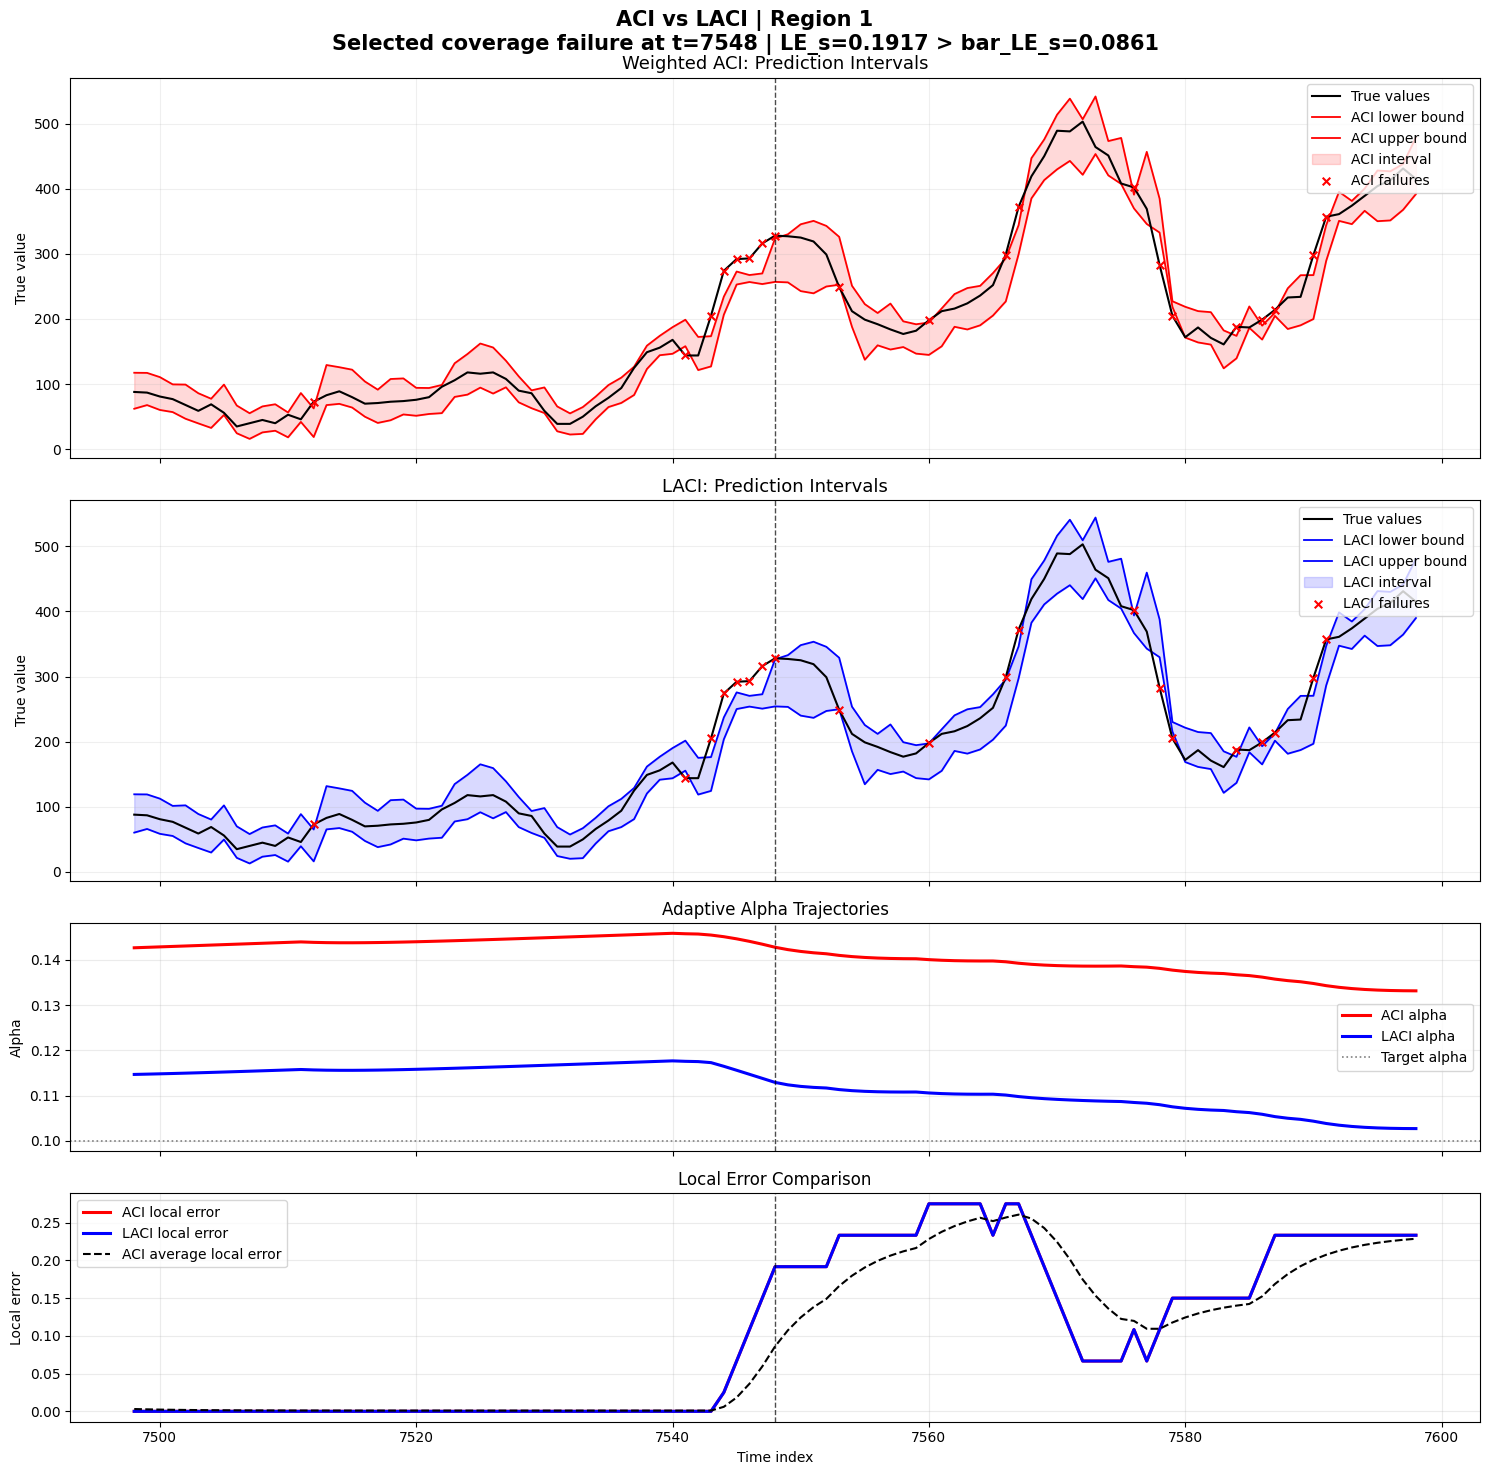

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_1_t7548.png


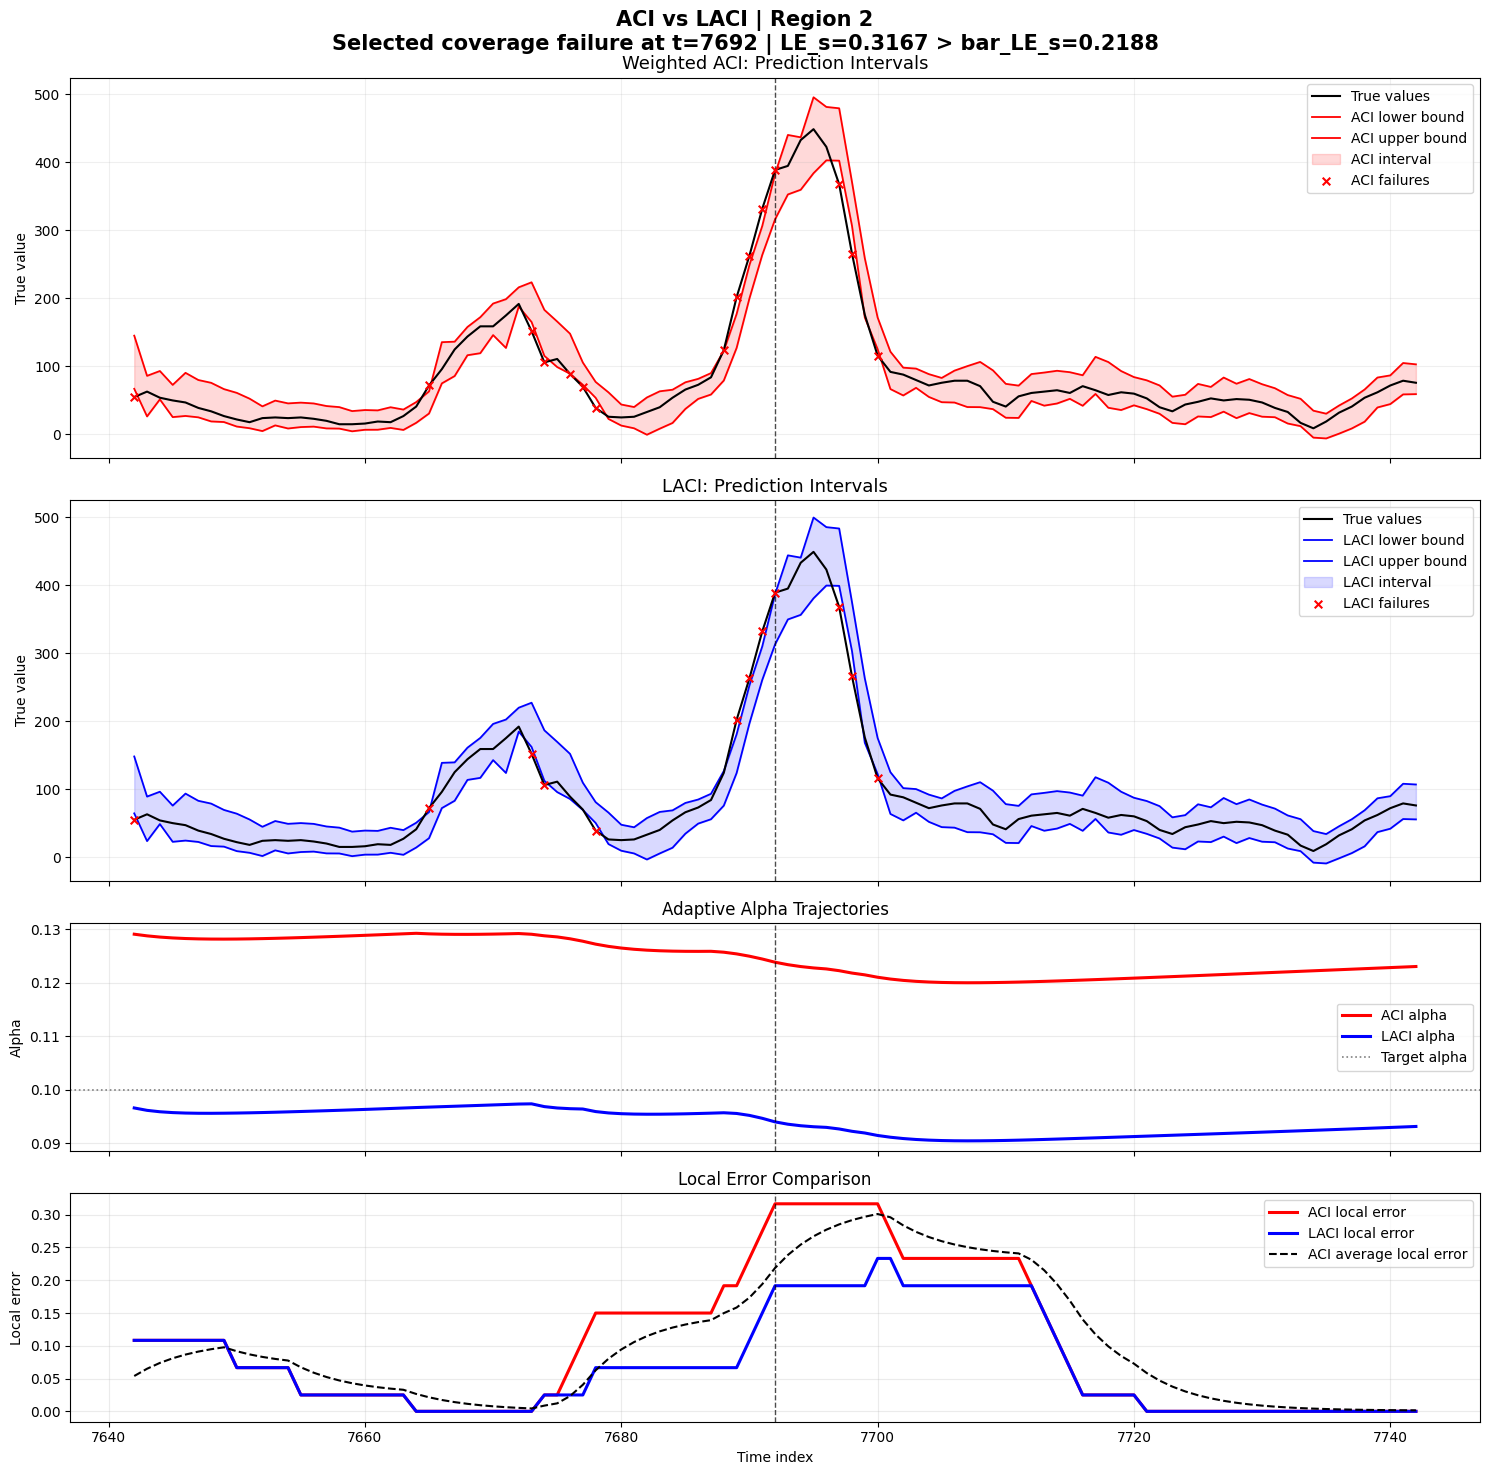

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_2_t7692.png


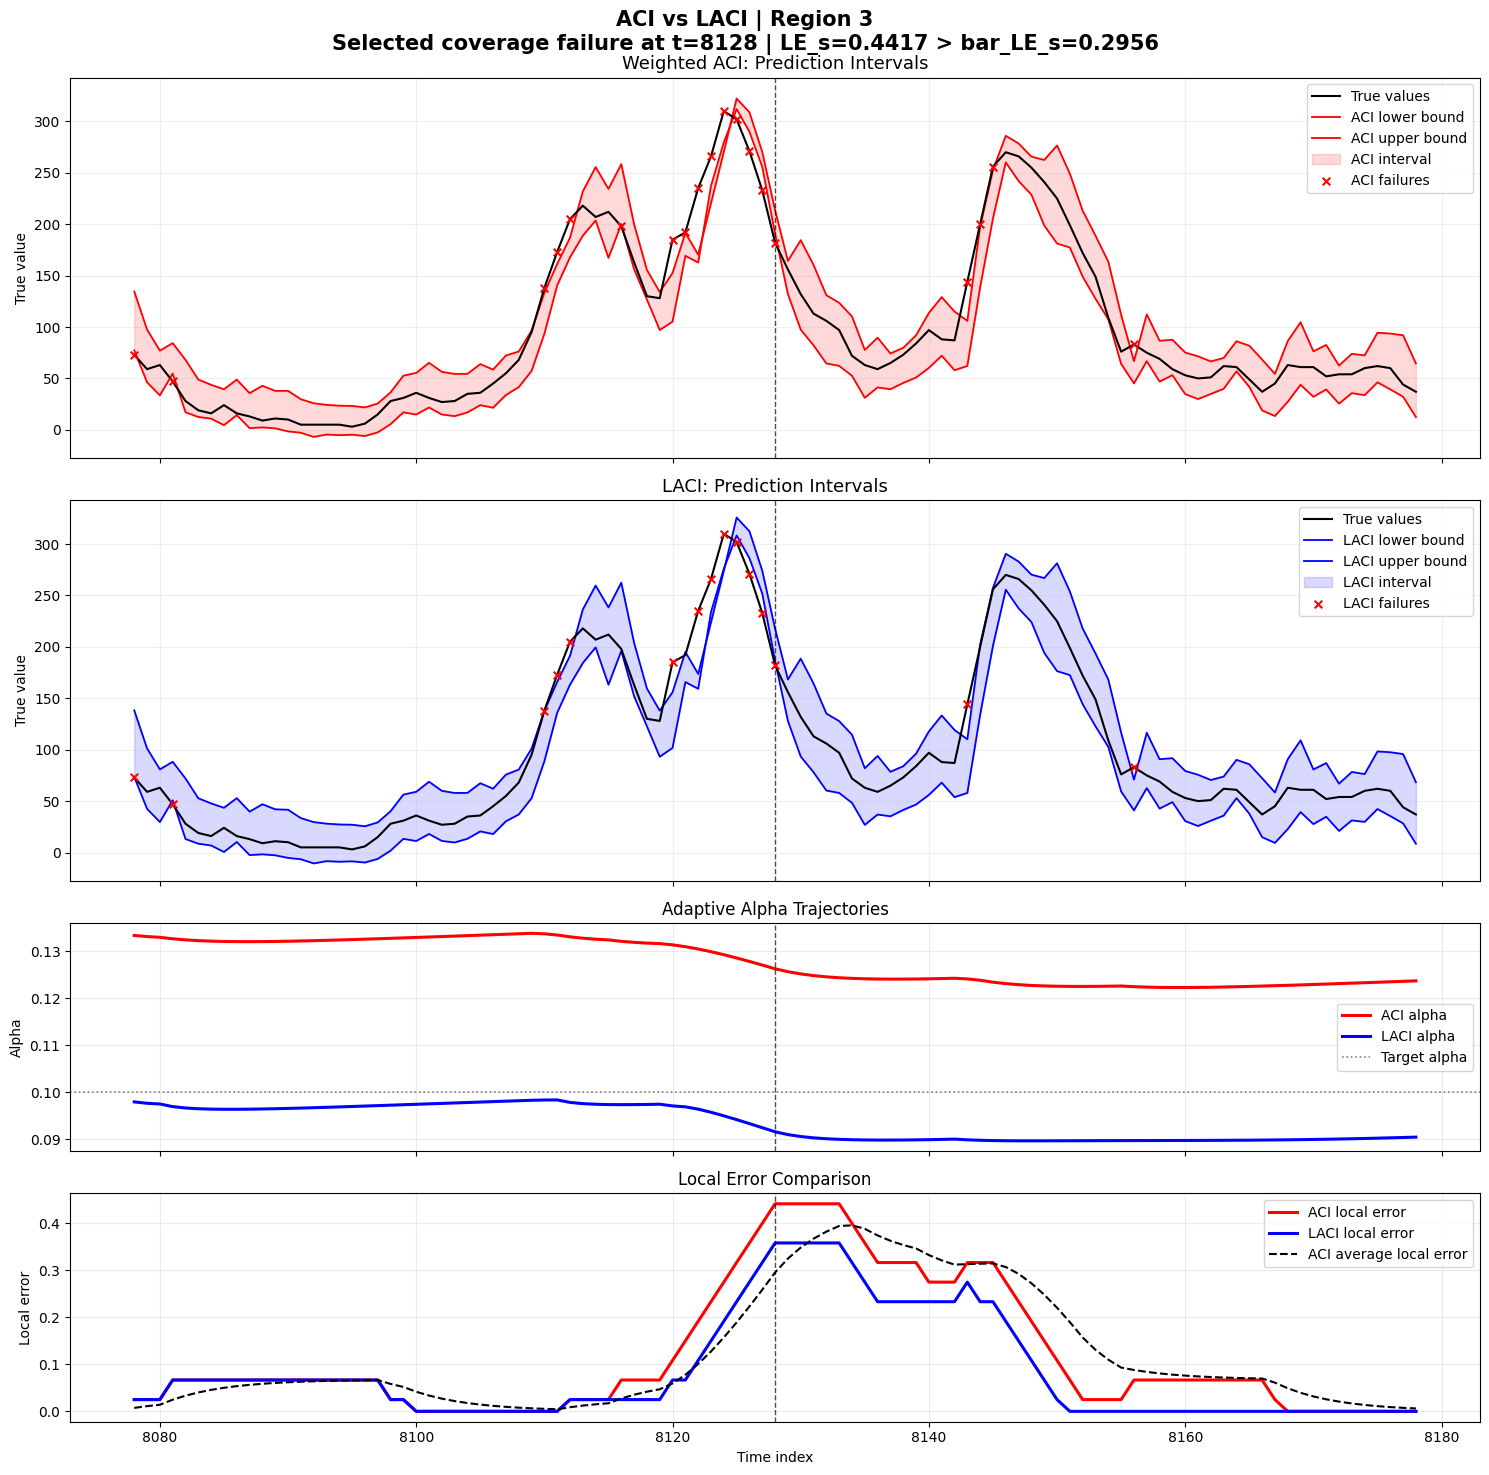

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_3_t8128.png


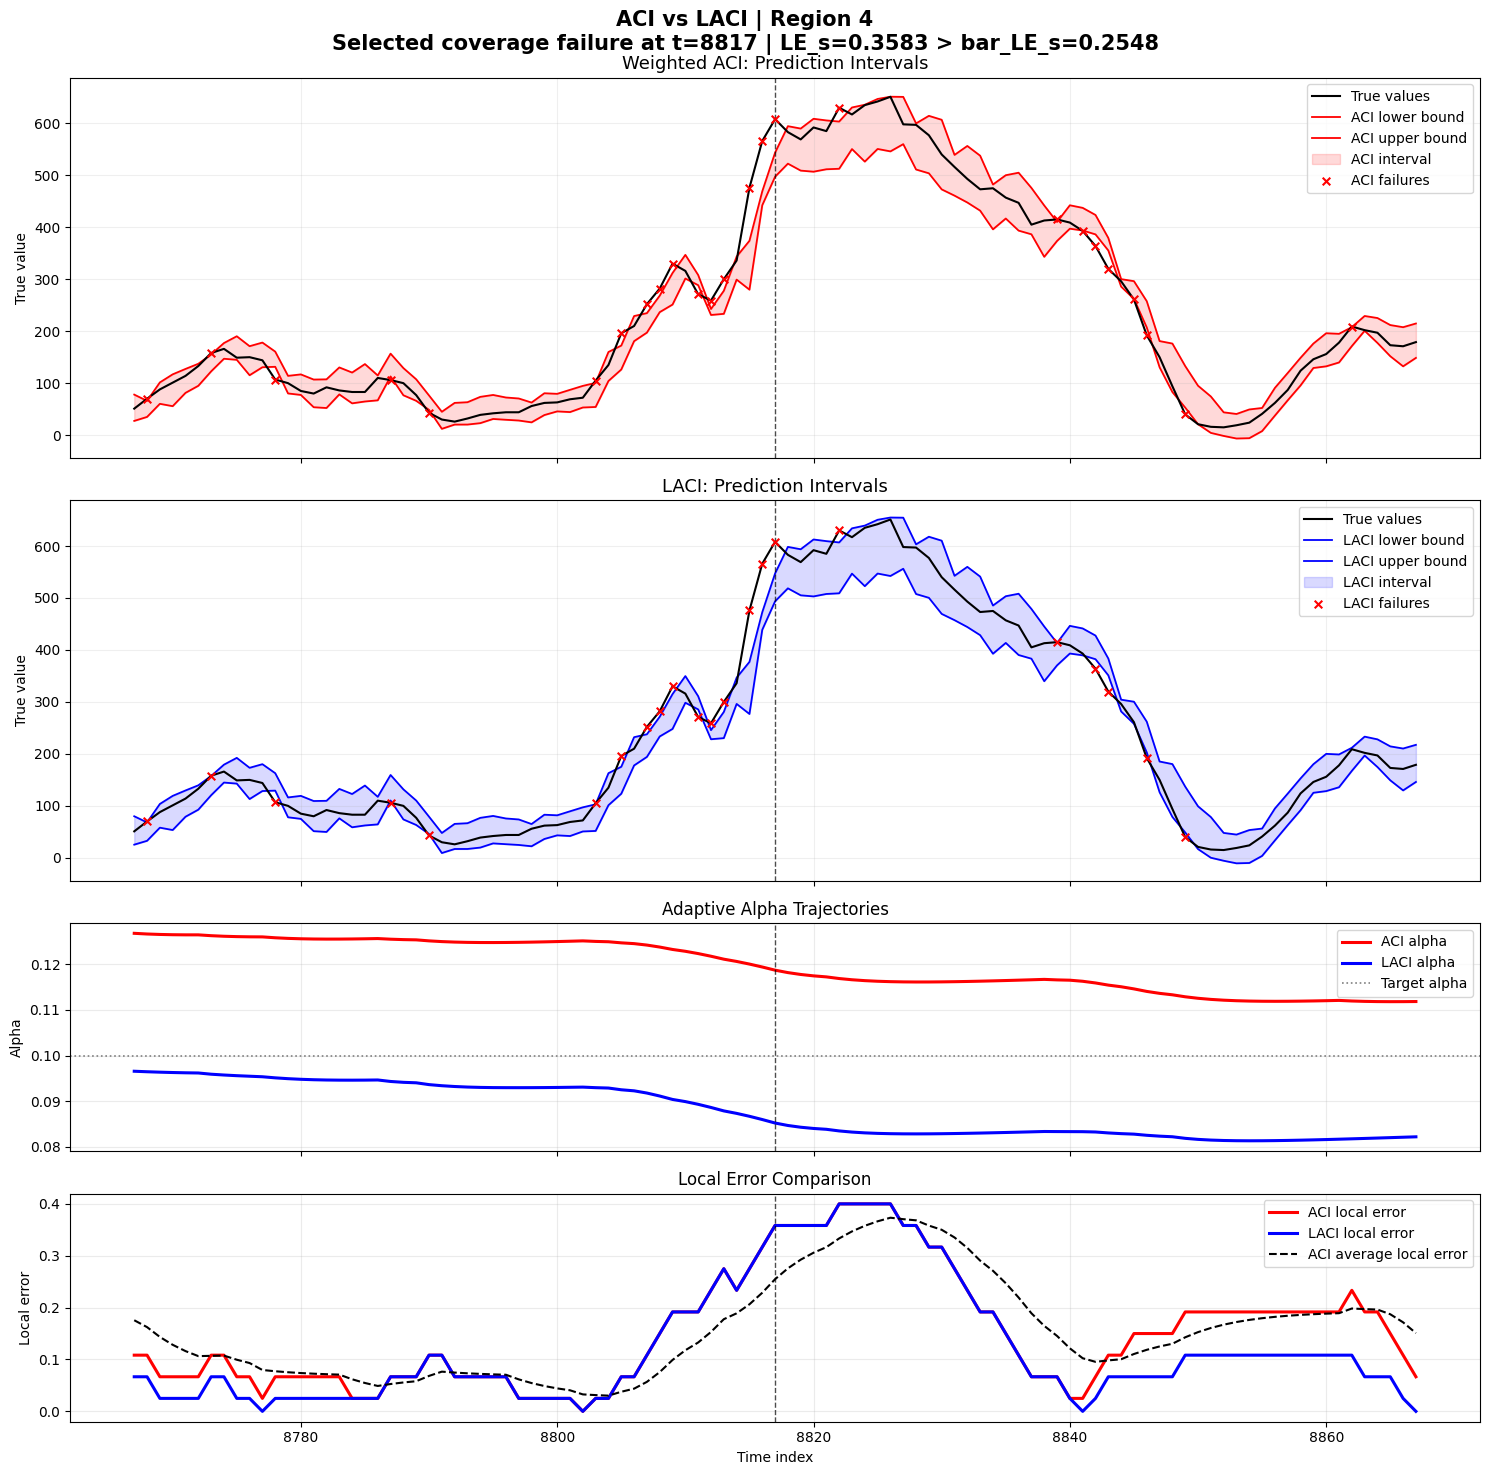

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_4_t8817.png


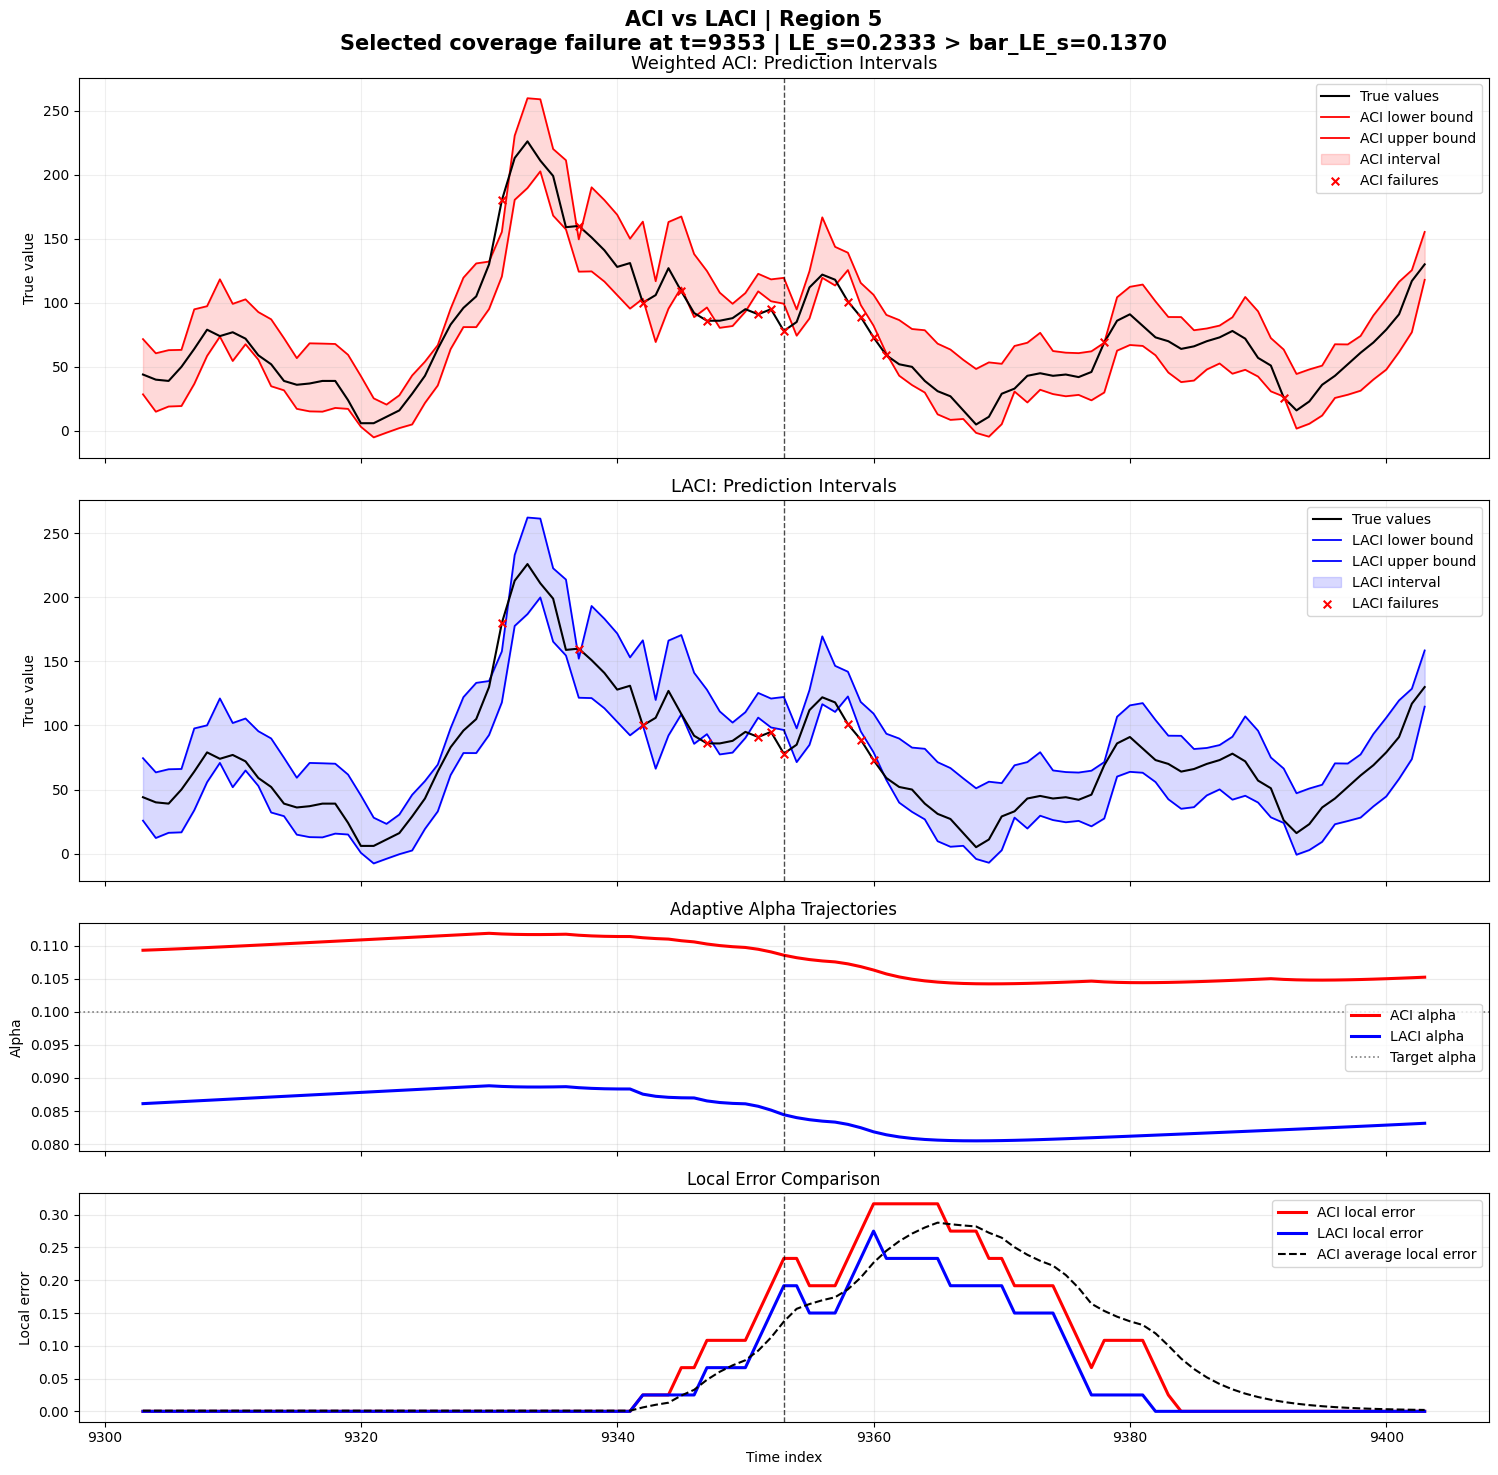

Saved: ./ACI_LACI_alpha_LE_regions\ACI_LACI_Comparison_Region_5_t9353.png


In [9]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ============================================================
# CONFIG
# ============================================================
DATASET_PATHS = [
    "../Datasets/50Hertz.csv",
    "../Datasets/Amprion.csv",
    "../Datasets/TenneTTSO.csv",
    "../Datasets/TransnetBW.csv"

     
]
DATASET_TO_COMPARE = DATASET_PATHS[0]   # change if you want another dataset
N_REGIONS = 5                           # number of points/regions to visualize
CONTEXT_BEFORE = 50
CONTEXT_AFTER = 50
MIN_SEPARATION = 100                    # avoid overlapping selected regions

L = 24                     # local window already used in notebook
EPS = LACI_EPS                          # from your notebook
SAVE_DIR = "./ACI_LACI_alpha_LE_regions"
os.makedirs(SAVE_DIR, exist_ok=True)

# ============================================================
# HELPERS
# ============================================================

def reset_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def run_reproducibly(run_fn, full_dataset):
    reset_all_seeds(SEED)
    return run_fn(
        full_dataset,
        alpha=ALPHA,
        gamma=GAMMA,
        decay=DECAY,
        tinit=TINIT,
        splitSize=SPLIT
    )

def prepare_result(result, scaler):
    alpha_t, errors, upper, lower, y_true = result
    return {
        "alpha": np.asarray(alpha_t, dtype=float),
        "errors": np.asarray(errors, dtype=float),
        "upper": scaler.inverse_transform(np.asarray(upper).reshape(-1, 1)).ravel(),
        "lower": scaler.inverse_transform(np.asarray(lower).reshape(-1, 1)).ravel(),
        "y": scaler.inverse_transform(np.asarray(y_true).reshape(-1, 1)).ravel(),
    }

def rolling_lpicp_and_le(errors, alpha, window):
    """
    errors[t] = 1 if miscoverage, 0 if covered
    LPICP_s(L) = local empirical coverage over last L points
    LE_s(L) = max((1-alpha) - LPICP_s(L), 0)
            = max(local miscoverage - alpha, 0)
    """
    err_mean = pd.Series(errors).rolling(window=window, min_periods=window).mean().to_numpy()
    lpicp = 1.0 - err_mean
    le = np.maximum((1.0 - alpha) - lpicp, 0.0)
    return lpicp, le

def normalization_ratio_bar_le(le_values, decay, eps):
    """
    bar_LE_s(L) = Z_LACI_s / Z_ACI_s
    where
      Z_ACI_s  = sum delta^(...) * 1
      Z_LACI_s = sum delta^(...) * (LE + eps)
    implemented recursively.
    """
    z_aci = 0.0
    z_laci = 0.0
    bar_le = np.full(len(le_values), np.nan)

    for s in range(len(le_values)):
        if np.isfinite(le_values[s]):
            z_aci = decay * z_aci + 1.0
            z_laci = decay * z_laci + (le_values[s] + eps)
            bar_le[s] = z_laci / z_aci

    return bar_le

def select_shift_points(le_aci, bar_le_aci, n_regions, context_before, context_after, min_sep):
    """
    Select points where LE_s > bar_LE_s using ACI trajectory.
    Rank by largest positive gap.
    """
    gap = le_aci - bar_le_aci
    valid = (
    np.isfinite(gap)
    & (gap > 0)
    & (ACI["errors"] == 1)
)

    # keep enough context for plotting
    valid[:max(L, context_before)] = False
    valid[max(0, len(valid) - context_after):] = False

    candidates = np.flatnonzero(valid)
    ranked = candidates[np.argsort(gap[candidates])[::-1]]

    selected = []
    for s in ranked:
        if all(abs(s - prev) >= min_sep for prev in selected):
            selected.append(int(s))
        if len(selected) >= n_regions:
            break

    selected.sort()
    return selected, gap

# ============================================================
# 1. LOAD DATASET AND RUN BOTH METHODS
# ============================================================

full_dataset, scaler, _, _ = load_dataset(DATASET_TO_COMPARE, seq_len=SEQ_LEN)

print("Running Weighted ACI...")
aci_raw = run_reproducibly(run_weighted_aci, full_dataset)

print("Running LACI...")
laci_raw = run_reproducibly(run_laci, full_dataset)

ACI = prepare_result(aci_raw, scaler)
LACI = prepare_result(laci_raw, scaler)

assert len(ACI["errors"]) == len(LACI["errors"])
N = len(ACI["errors"])

# This is the forecasting time index corresponding to alpha/error trajectories
time_index = np.arange(N) + TINIT

# ============================================================
# 2. COMPUTE LPICP, LE, AND bar_LE
# ============================================================

LPICP_aci, LE_aci = rolling_lpicp_and_le(ACI["errors"], ALPHA, L)
LPICP_laci, LE_laci = rolling_lpicp_and_le(LACI["errors"], ALPHA, L)

# IMPORTANT:
# We select points based on the ACI trajectory.
bar_LE_aci = normalization_ratio_bar_le(LE_aci, DECAY, EPS)

# ============================================================
# 3. SELECT POINTS s WHERE LE_s(L) > bar_LE_s(L)
# ============================================================

selected_points, gap = select_shift_points(
    LE_aci, bar_LE_aci,
    n_regions=N_REGIONS,
    context_before=CONTEXT_BEFORE,
    context_after=CONTEXT_AFTER,
    min_sep=MIN_SEPARATION
)

print("\nSelected points where LE_s(L) > bar_LE_s(L) (based on ACI):")
for s in selected_points:
    print(
        f"trajectory_idx={s:5d} | "
        f"time={time_index[s]:5d} | "
        f"LE_s={LE_aci[s]:.6f} | "
        f"bar_LE_s={bar_LE_aci[s]:.6f} | "
        f"gap={gap[s]:.6f}"
    )

if len(selected_points) == 0:
    print("\nNo points found with LE_s(L) > bar_LE_s(L).")
    print("Try reducing MIN_SEPARATION or changing DATASET_TO_COMPARE.")
    
# ============================================================
# 4. SUMMARY TABLE
# ============================================================

summary_rows = []

for s in selected_points:
    left = s - CONTEXT_BEFORE
    right = s + CONTEXT_AFTER + 1

    pre_alpha_aci = ACI["alpha"][s - 1] if s > 0 else ALPHA
    pre_alpha_laci = LACI["alpha"][s - 1] if s > 0 else ALPHA

    summary_rows.append({
        "time": int(time_index[s]),
        "trajectory_idx": int(s),
        "LE_s_ACI": float(LE_aci[s]),
        "bar_LE_s_ACI": float(bar_LE_aci[s]),
        "ACI_alpha_at_s": float(ACI["alpha"][s]),
        "LACI_alpha_at_s": float(LACI["alpha"][s]),
        "ACI_alpha_drop_at_s": float(pre_alpha_aci - ACI["alpha"][s]),
        "LACI_alpha_drop_at_s": float(pre_alpha_laci - LACI["alpha"][s]),
        "ACI_mean_LE_region": float(np.nanmean(LE_aci[left:right])),
        "LACI_mean_LE_region": float(np.nanmean(LE_laci[left:right])),
        "ACI_mean_LPICP_region": float(np.nanmean(LPICP_aci[left:right])),
        "LACI_mean_LPICP_region": float(np.nanmean(LPICP_laci[left:right]))
    })

summary_df = pd.DataFrame(summary_rows)

if len(summary_df) > 0:
    print("\n===== Summary comparison =====")
    print(summary_df.round(6).to_string(index=False))
    summary_df.to_csv(os.path.join(SAVE_DIR, "alpha_LE_region_summary.csv"), index=False)
    print(f"\nSaved summary CSV to: {os.path.join(SAVE_DIR, 'alpha_LE_region_summary.csv')}")

# ============================================================
# 5. PLOT ALPHA AND LOCAL ERROR AROUND EACH SELECTED POINT
# ============================================================


# ============================================================
# 5. PLOT FOUR PANELS FOR EACH SELECTED REGION
# ============================================================

for ridx, s in enumerate(selected_points, start=1):

    left = s - CONTEXT_BEFORE
    right = s + CONTEXT_AFTER + 1

    xx = time_index[left:right]
    yy = ACI["y"][left:right]

    fig, axes = plt.subplots(
        4, 1,
        figsize=(15, 15),
        sharex=True,
        gridspec_kw={
            "height_ratios": [2, 2, 1.2, 1.2]
        }
    )

    # ========================================================
    # PANEL 1: ACI PREDICTION INTERVAL
    # ========================================================

    ax = axes[0]

    ax.plot(
        xx, yy,
        color="black",
        linewidth=1.5,
        label="True values",
        zorder=3
    )

    ax.plot(
        xx, ACI["lower"][left:right],
        color="red",
        linewidth=1.3,
        label="ACI lower bound"
    )

    ax.plot(
        xx, ACI["upper"][left:right],
        color="red",
        linewidth=1.3,
        label="ACI upper bound"
    )

    ax.fill_between(
        xx,
        ACI["lower"][left:right],
        ACI["upper"][left:right],
        color="red",
        alpha=0.15,
        label="ACI interval"
    )

    # Highlight ACI coverage failures
    aci_fail = ACI["errors"][left:right] == 1

    ax.scatter(
        xx[aci_fail],
        yy[aci_fail],
        color="red",
        marker="x",
        s=30,
        zorder=5,
        label="ACI failures"
    )

    ax.set_title(
        "Weighted ACI: Prediction Intervals",
        fontsize=13
    )

    ax.set_ylabel("True value")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

    # ========================================================
    # PANEL 2: LACI PREDICTION INTERVAL
    # ========================================================

    ax = axes[1]

    ax.plot(
        xx, yy,
        color="black",
        linewidth=1.5,
        label="True values",
        zorder=3
    )

    ax.plot(
        xx, LACI["lower"][left:right],
        color="blue",
        linewidth=1.3,
        label="LACI lower bound"
    )

    ax.plot(
        xx, LACI["upper"][left:right],
        color="blue",
        linewidth=1.3,
        label="LACI upper bound"
    )

    ax.fill_between(
        xx,
        LACI["lower"][left:right],
        LACI["upper"][left:right],
        color="blue",
        alpha=0.15,
        label="LACI interval"
    )

    # Highlight LACI coverage failures
    laci_fail = LACI["errors"][left:right] == 1

    ax.scatter(
        xx[laci_fail],
        yy[laci_fail],
        color="red",
        marker="x",
        s=30,
        zorder=5,
        label="LACI failures"
    )

    ax.set_title(
        "LACI: Prediction Intervals",
        fontsize=13
    )

    ax.set_ylabel("True value")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

    # Equal y-axis scaling for fair comparison
    all_y = np.concatenate([
        yy,
        ACI["lower"][left:right],
        ACI["upper"][left:right],
        LACI["lower"][left:right],
        LACI["upper"][left:right]
    ])

    y_min = np.nanmin(all_y)
    y_max = np.nanmax(all_y)
    padding = max(0.05 * (y_max - y_min), 1e-6)

    axes[0].set_ylim(y_min-padding, y_max+padding)
    axes[1].set_ylim(y_min-padding, y_max+padding)

    # ========================================================
    # PANEL 3: ALPHA TRAJECTORY
    # ========================================================

    ax = axes[2]

    ax.plot(
        xx,
        ACI["alpha"][left:right],
        color="red",
        linewidth=2.2,
        label="ACI alpha"
    )

    ax.plot(
        xx,
        LACI["alpha"][left:right],
        color="blue",
        linewidth=2.2,
        label="LACI alpha"
    )

    ax.axhline(
        ALPHA,
        color="gray",
        linestyle=":",
        linewidth=1.2,
        label="Target alpha"
    )

    ax.set_title("Adaptive Alpha Trajectories")
    ax.set_ylabel("Alpha")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)

    # ========================================================
    # PANEL 4: LOCAL ERROR TRAJECTORY
    # ========================================================

    ax = axes[3]

    ax.plot(
        xx,
        LE_aci[left:right],
        color="red",
        linewidth=2.2,
        label="ACI local error"
    )

    ax.plot(
        xx,
        LE_laci[left:right],
        color="blue",
        linewidth=2.2,
        label="LACI local error"
    )

    ax.plot(
        xx,
        bar_LE_aci[left:right],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="ACI average local error"
    )

    ax.set_title("Local Error Comparison")
    ax.set_ylabel("Local error")
    ax.set_xlabel("Time index")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)

    # ========================================================
    # SELECTED POINT MARKER
    # ========================================================

    for ax in axes:
        ax.axvline(
            time_index[s],
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7
        )

    # ========================================================
    # TITLE AND SAVE
    # ========================================================

    fig.suptitle(
        f"ACI vs LACI | Region {ridx}\n"
        f"Selected coverage failure at t={time_index[s]} | "
        f"LE_s={LE_aci[s]:.4f} > "
        f"bar_LE_s={bar_LE_aci[s]:.4f}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    save_path = os.path.join(
        SAVE_DIR,
        f"ACI_LACI_Comparison_Region_{ridx}_t{time_index[s]}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved: {save_path}")


Generated observations: 5000
   start   end      type  magnitude
0   2300  2432  variance   4.951245
1   3000  3216      mean   5.358193
2   3350  3537  variance   3.900772
3   3700  3836      mean   5.780295
4   4400  4568  variance   4.287730


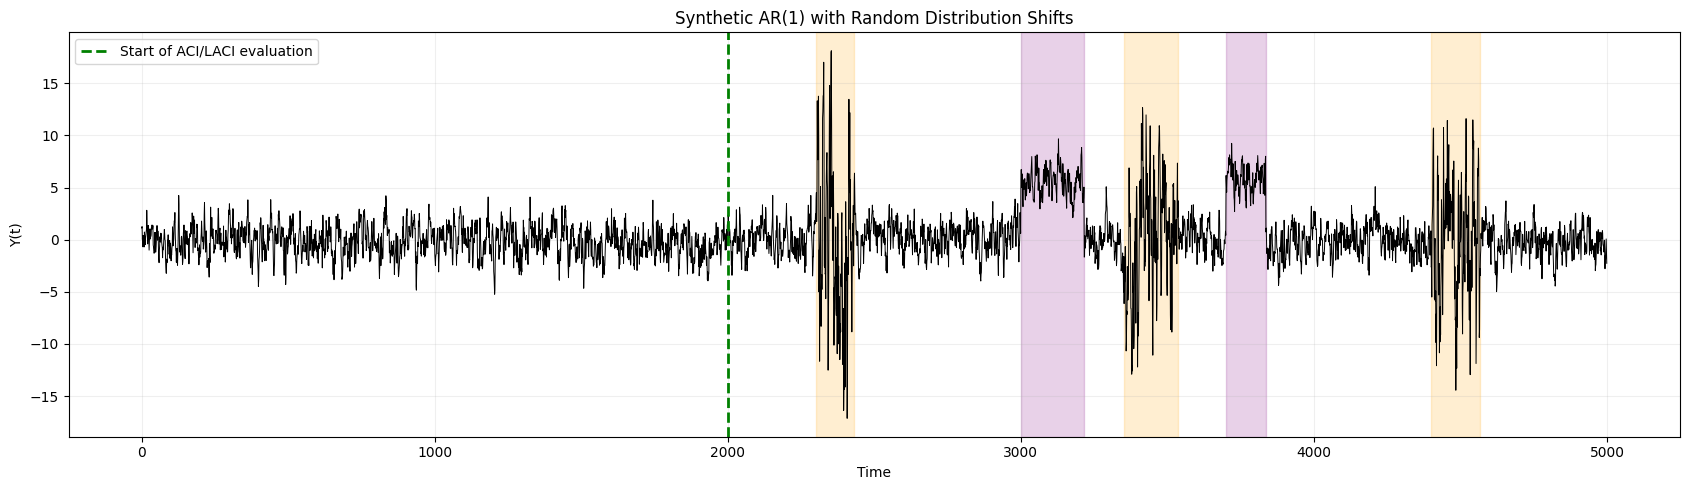

In [1]:
#With AR process 


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SYNTHETIC AR(1) WITH RANDOM DISTRIBUTION SHIFTS
# ============================================================

SEED = 42
rng = np.random.default_rng(SEED)

T = 5000
PHI = 0.7

mu = np.zeros(T)
sigma = np.ones(T)

# Randomly select shifts inside the evaluation portion.
# These are separated so individual shift effects can be studied.
shift_candidates = np.arange(2300, 4600, 350)
shift_points = np.sort(
    rng.choice(shift_candidates, size=5, replace=False)
)

shift_records = []

for i, start in enumerate(shift_points):

    duration = int(rng.integers(120, 251))
    end = min(start + duration, T)

    if i % 2 == 0:
        # Variance shift
        magnitude = float(rng.uniform(3.0, 5.0))
        sigma[start:end] = magnitude
        shift_type = "variance"

    else:
        # Mean shift
        magnitude = float(
            rng.choice([-1, 1]) * rng.uniform(3.0, 6.0)
        )
        mu[start:end] = magnitude
        shift_type = "mean"

    shift_records.append({
        "start": int(start),
        "end": int(end),
        "type": shift_type,
        "magnitude": magnitude
    })

# Generate AR(1) observations
y = np.zeros(T)
y[0] = rng.normal(mu[0], sigma[0])

for t in range(1, T):
    y[t] = (
        mu[t]
        + PHI * (y[t-1] - mu[t-1])
        + sigma[t] * rng.normal()
    )

df = pd.DataFrame({
    "time": np.arange(T),
    "Power": y,
    "mu": mu,
    "sigma": sigma
})

df.to_csv("synthetic_AR1_shifts.csv", index=False)

print("Generated observations:", len(df))
print(pd.DataFrame(shift_records))

# ============================================================
# VISUALIZE THE FULL SERIES
# ============================================================

plt.figure(figsize=(17, 5))

plt.plot(
    df["time"], df["Power"],
    color="black", linewidth=0.7
)

for shift in shift_records:
    color = (
        "orange" if shift["type"] == "variance"
        else "purple"
    )

    plt.axvspan(
        shift["start"],
        shift["end"],
        color=color,
        alpha=0.18
    )

plt.axvline(
    2000,
    color="green",
    linestyle="--",
    linewidth=2,
    label="Start of ACI/LACI evaluation"
)

plt.title("Synthetic AR(1) with Random Distribution Shifts")
plt.xlabel("Time")
plt.ylabel("Y(t)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [4]:

import torch
import random
from sklearn.preprocessing import StandardScaler

# ============================================================
# PREPARE DATA
# ============================================================

SEQ_LEN = 48
SYNTHETIC_TINIT = T - SEQ_LEN - 3000

assert SYNTHETIC_TINIT > 0

# Scale using only the initial history to avoid future leakage
scaler = StandardScaler()
scaler.fit(y[:2000].reshape(-1, 1))

y_scaled = scaler.transform(
    y.reshape(-1, 1)
).flatten().astype(np.float32)

full_dataset = SeqDataset(y_scaled, SEQ_LEN)

assert len(full_dataset) - SYNTHETIC_TINIT == 3000

# ============================================================
# RUN BOTH METHODS
# ============================================================

def run_synthetic(fn):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    return fn(
        full_dataset,
        alpha=ALPHA,
        gamma=GAMMA,
        decay=DECAY,
        tinit=SYNTHETIC_TINIT,
        splitSize=SPLIT
    )

print("Running Weighted ACI...")
aci_raw = run_synthetic(run_weighted_aci)

print("Running LACI...")
laci_raw = run_synthetic(run_laci)

print("ACI observations:", len(aci_raw[0]))
print("LACI observations:", len(laci_raw[0]))


Running Weighted ACI...
[Weighted_ACI] t=2000, alphat=0.0999, weighted_err=0.0340
[Weighted_ACI] t=2200, alphat=0.1066, weighted_err=0.1939
[Weighted_ACI] t=2400, alphat=0.0398, weighted_err=0.0011
[Weighted_ACI] t=2600, alphat=0.0598, weighted_err=0.0000
[Weighted_ACI] t=2800, alphat=0.0798, weighted_err=0.0000
[Weighted_ACI] t=3000, alphat=0.0791, weighted_err=0.0776
[Weighted_ACI] t=3200, alphat=0.0768, weighted_err=0.0001
[Weighted_ACI] t=3400, alphat=0.0633, weighted_err=0.1148
[Weighted_ACI] t=3600, alphat=0.0648, weighted_err=0.0000
[Weighted_ACI] t=3800, alphat=0.0778, weighted_err=0.0088
[Weighted_ACI] t=4000, alphat=0.0968, weighted_err=0.0000
[Weighted_ACI] t=4200, alphat=0.1118, weighted_err=0.0000
[Weighted_ACI] t=4400, alphat=0.1091, weighted_err=0.0638
[Weighted_ACI] t=4600, alphat=0.0924, weighted_err=0.1610
[Weighted_ACI] t=4800, alphat=0.1038, weighted_err=0.0002
Running LACI...
[LACI] t=2000, alphat=0.0989, weighted_err=0.0169
[LACI] t=2200, alphat=0.1026, weighted_e